# $Types$ $of$ $Feature$ $Scaling$ :-
### 1. Standardization.
### 2. Normalization.

In [85]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. $Standardization$ :-

In [88]:
df = pd.read_csv('Social_Network_Ads.csv')
df = df.iloc[:,2:]

In [90]:
df.sample(8)

,Age,EstimatedSalary,Purchased
79,26,17000,0
93,29,28000,0
77,22,27000,0
55,24,55000,0
180,26,16000,0
188,35,72000,0
25,47,20000,1
189,28,32000,0


## Train test split

In [93]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop('Purchased', axis=1), df['Purchased'], test_size=0.3, random_state=0)


In [95]:
x_train.shape, x_test.shape

((280, 2), (120, 2))

## Standard Scaler

In [98]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# fit the scaler to the training set, it will learn the parameters
scaler.fit(x_train)

# transform train and test sets
x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [100]:
scaler.mean_

array([3.78642857e+01, 6.98071429e+04])

In [102]:
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns)

In [104]:
np.round(x_train.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,37.9,69807.1
std,10.2,34641.2
min,18.0,15000.0
25%,30.0,43000.0
50%,37.0,70500.0
75%,46.0,88000.0
max,60.0,150000.0


In [106]:
np.round(x_train_scaled.describe(), 1)

,Age,EstimatedSalary
count,280.0,280.0
mean,0.0,0.0
std,1.0,1.0
min,-1.9,-1.6
25%,-0.8,-0.8
50%,-0.1,0.0
75%,0.8,0.5
max,2.2,2.3


## Effect of Scaling

[Text(0.5, 1.0, 'Before Scaling')]

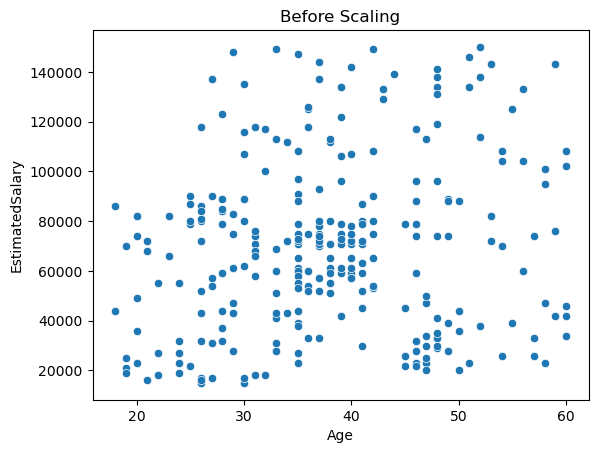

In [109]:
sns.scatterplot(x=x_train.Age, y=x_train.EstimatedSalary).set(title="Before Scaling")

[Text(0.5, 1.0, 'After Scaling')]

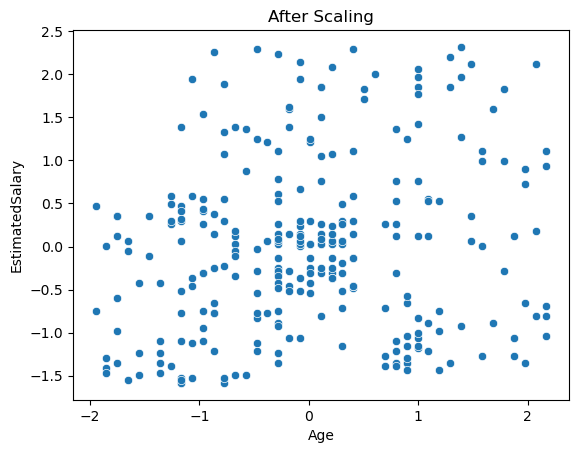

In [111]:
sns.scatterplot(x=x_train_scaled.Age, y=x_train_scaled.EstimatedSalary).set(title="After Scaling")

<Axes: xlabel='Age', ylabel='Density'>

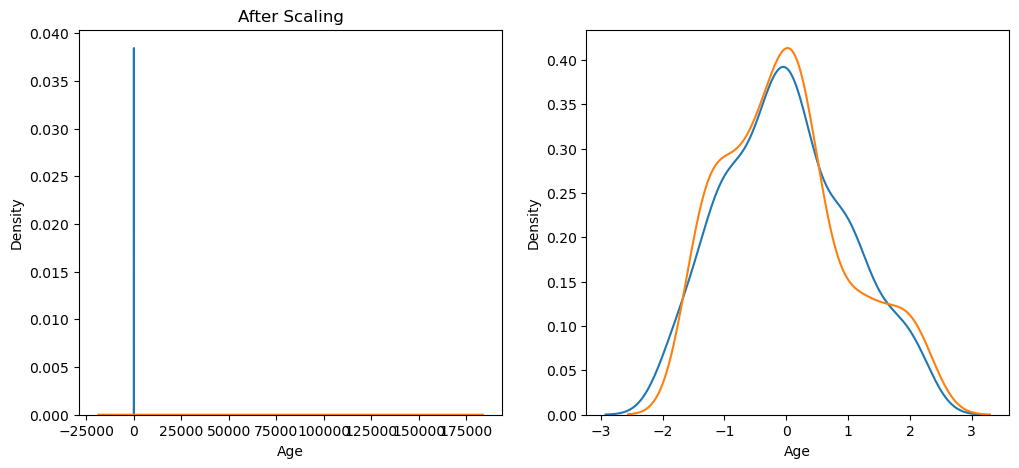

In [113]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax[0].set_title('Before Scaling')
sns.kdeplot(x_train.Age, ax = ax[0])
sns.kdeplot(x_train.EstimatedSalary, ax = ax[0])

# After scaling
ax[0].set_title('After Scaling')
sns.kdeplot(x_train_scaled.Age, ax = ax[1])
sns.kdeplot(x_train_scaled.EstimatedSalary, ax = ax[1])

<Axes: xlabel='Age', ylabel='Density'>

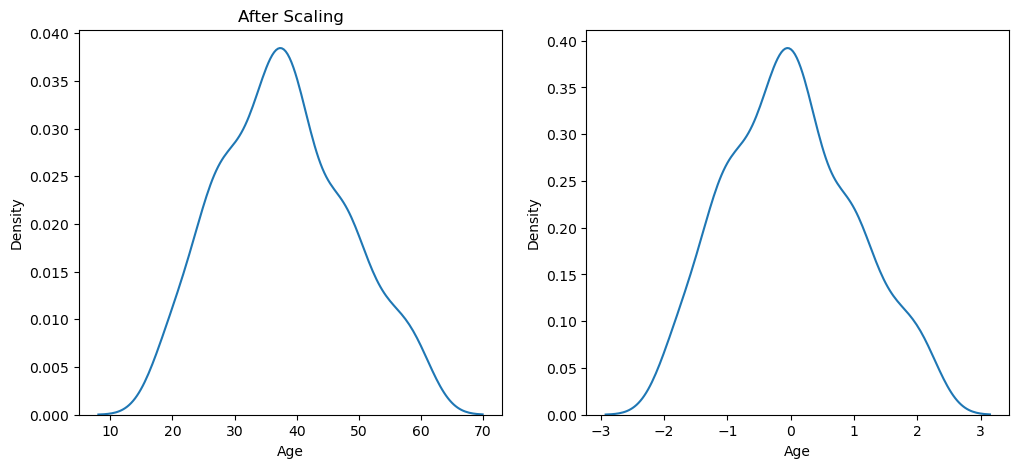

In [115]:
fig, ax = plt.subplots(ncols=2, figsize=(12, 5))

# before scaling
ax[0].set_title('Before Scaling')
sns.kdeplot(x_train.Age, ax = ax[0])

# After scaling
ax[0].set_title('After Scaling')
sns.kdeplot(x_train_scaled.Age, ax = ax[1])

## Why scaling is important?

In [118]:
from sklearn.linear_model import LogisticRegression

In [120]:
lr = LogisticRegression()
lr_scaled = LogisticRegression()

In [122]:
lr.fit(x_train, y_train)
lr_scaled.fit(x_train_scaled, y_train)

LogisticRegression()

In [124]:
y_pred = lr.predict(x_test)
y_pred_scaled = lr_scaled.predict(x_test_scaled)

In [126]:
from sklearn.metrics import accuracy_score

In [128]:
print("Actual :", accuracy_score(y_test, y_pred))
print("Scaled :", accuracy_score(y_test, y_pred_scaled))

Actual : 0.875
Scaled : 0.8666666666666667


## Though scaled here do not show much resuld but it is important to do scaling

## In some cases like in decision scaling done or not done doesnt matter

In [144]:
from sklearn.tree import DecisionTreeClassifier

In [146]:
dt = DecisionTreeClassifier(random_state=42)
dt_scaled = DecisionTreeClassifier(random_state=42)

In [148]:
dt.fit(x_train, y_train)
dt_scaled.fit(x_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [150]:
y_pred = dt.predict(x_test)
y_pred_scaled = dt_scaled.predict(x_test_scaled)

In [152]:
print("Actual :", accuracy_score(y_test, y_pred))
print("Scaled :", accuracy_score(y_test, y_pred_scaled))

Actual : 0.875
Scaled : 0.8666666666666667


In [154]:
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


# Effect of Outlier

In [161]:
new_data = pd.DataFrame({
    'Age': [5, 90, 95],
    'EstimatedSalary': [1000, 250000, 350000],
    'Purchased': [0, 1, 1]
})

df = pd.concat([df, new_data], ignore_index=True)


In [163]:
df

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
398,36,33000,0
399,49,36000,1
400,5,1000,0
401,90,250000,1


<Axes: xlabel='Age', ylabel='EstimatedSalary'>

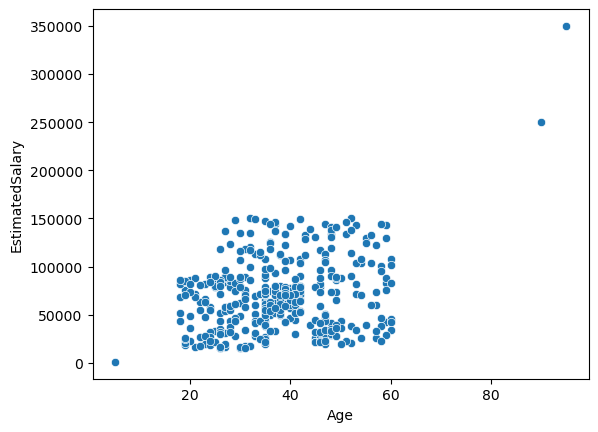

In [167]:
sns.scatterplot(x=df.Age, y=df.EstimatedSalary)

In [169]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr_scaled = LogisticRegression()

lr.fit(x_train, y_train)
lr_scaled.fit(x_train_scaled, y_train)

y_pred = dt.predict(x_test)
y_pred_scaled = dt_scaled.predict(x_test_scaled)

from sklearn.metrics import accuracy_score

print("Actual :", accuracy_score(y_test, y_pred))
print("Scaled :", accuracy_score(y_test, y_pred_scaled))

Actual : 0.875
Scaled : 0.8666666666666667


# 1. $Normalization$ :-
Normalization is a technique often applied as part of data preparation for machine learning. The goal of normalization is to change the values of numeric colunms in the dataset to use a common scale, without distorting differences in the ranges of values or losing information.

## a. MinMax Scaling

In [197]:
df = pd.read_csv('wine_data.csv', usecols=[0, 1, 2])

In [199]:
df

,class_label,alcohol,malic_acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59
...,...,...,...
173,3,13.71,5.65
174,3,13.40,3.91
175,3,13.27,4.28
176,3,13.17,2.59


<Axes: xlabel='alcohol', ylabel='Density'>

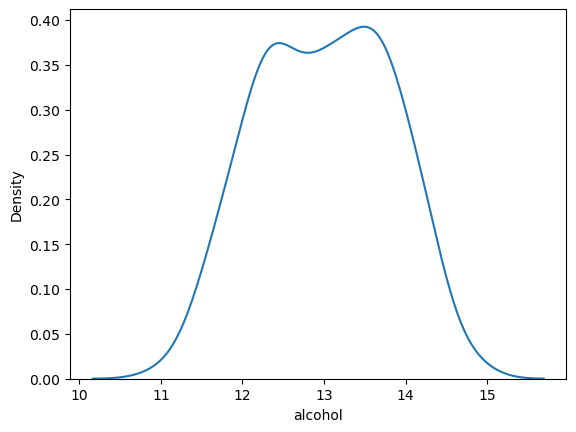

In [203]:
sns.kdeplot(x=df.alcohol)

<Axes: xlabel='malic_acid', ylabel='Density'>

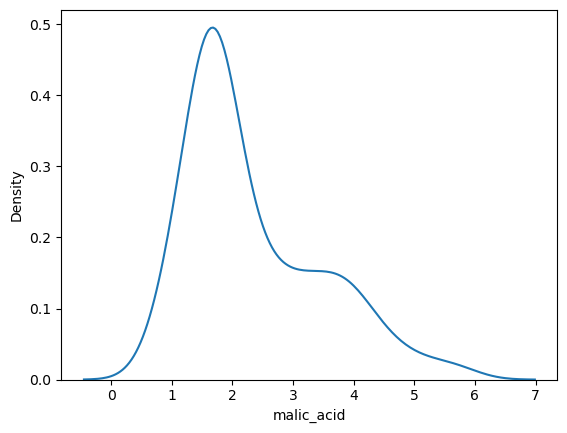

In [205]:
sns.kdeplot(df.malic_acid)

<Axes: xlabel='alcohol', ylabel='malic_acid'>

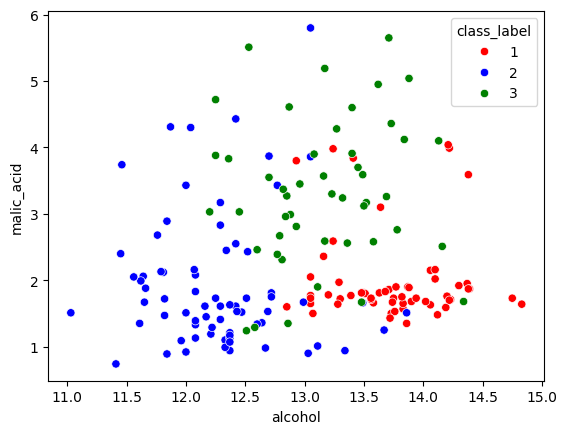

In [211]:
color_dict = {1:'red', 2:'blue', 3:'green'}
sns.scatterplot(data=df, x='alcohol', y='malic_acid', hue='class_label', palette=color_dict)



In [214]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(df.drop('class_label', axis=1),
                                                   df.class_label,
                                                   test_size=0.3,
                                                    random_state=0)



In [216]:
x_train.shape, x_test.shape

((124, 2), (54, 2))

In [220]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

# fit the scaler to the train set, it will learn the parameters
scaler.fit(x_train)

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [222]:
x_train_scaled = pd.DataFrame(x_train_scaled, columns=x_train.columns)
x_test_scaled = pd.DataFrame(x_test_scaled, columns=x_test.columns)

In [224]:
np.round(x_train.describe(), 1)

,alcohol,malic_acid
count,124.0,124.0
mean,13.0,2.4
std,0.8,1.1
min,11.0,0.9
25%,12.4,1.6
50%,13.0,1.9
75%,13.6,3.2
max,14.8,5.6


In [226]:
np.round(x_train_scaled.describe(), 1)

,alcohol,malic_acid
count,124.0,124.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


## b. Mean Normalization
xi = (xi - mean) / (xmax - xmin)

##
## c. MaxAbsolute Scaling
xi = xi / | xmax |
                
use when we have sparse data

##
## d. Robust Scaling
xi = (xi - xmedian) / IQR
                    
robust to outliers
